# A nota de viralidade prevê as views?

**Contexto.** Numa operação real de cortes de vídeo para Shorts e TikTok (três nichos: ciência, negócios e games),
cada corte recebe, antes de ser publicado, uma **nota de viralidade** entre 0 e 1. A nota combina a avaliação de um
juiz de IA (oito critérios) com métricas do vídeo de origem. Ela decide o que é renderizado e publicado primeiro.

**Pergunta.** Essa nota acerta? Cortes com nota mais alta têm mais views?

**Dados.** Extratos anonimizados da operação (sem títulos, canais de origem ou links): 680 cortes pontuados e as
métricas dos posts que já foram ao ar, coletadas diariamente.

**O que este notebook mostra:** a resposta muda três vezes conforme a comparação fica mais justa, e a conclusão
honesta, com a amostra de hoje, é "ainda não dá para saber". O valor do estudo está em mostrar por quê, e em dizer
exatamente quanto dado falta.

Esta é uma análise viva: `scripts/extrair_dados.py` e `scripts/rodar_analise.py` refazem tudo com a coleta mais
recente. Os números abaixo são da coleta indicada na primeira célula.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from nota_viral import analise, dados, graficos

pd.set_option("display.float_format", lambda v: f"{v:.3f}")


def mostrar(figura):
    display(figura)
    plt.close(figura)


cortes, posts, agenda = dados.carregar_cortes(), dados.carregar_posts(), dados.carregar_agenda()
tabela = dados.juntar(cortes, posts)
pd.Series(analise.resumo_da_amostra(cortes, tabela, posts), name="valor").to_frame()

,valor
cortes_pontuados,680
posts_com_metricas,64
cortes_publicados,35
coletas,2
coleta_usada,2026-11-10
horas_no_ar_mediana,39.400


## 1. A resposta ingênua: sim, e com folga

Juntando todos os posts e medindo a correlação de postos (Spearman) entre a nota e as views:

In [2]:
correlacoes = analise.correlacoes(tabela)
ingenua = correlacoes.loc["Tudo junto (ingênua)"]
print(f"Correlação: {ingenua['correlação']:.2f}  IC 95% [{ingenua['IC 95% inferior']:.2f} ; {ingenua['IC 95% superior']:.2f}]  p = {ingenua['p']:.3f}")

Correlação: 0.38  IC 95% [0.13 ; 0.60]  p = 0.002


Correlação de 0,38 com p = 0,002. Quem parasse aqui escreveria "a nota prevê as views". O problema é o que
está misturado nesse número.

## 2. Primeira correção: cada canal joga numa faixa diferente

Um "canal" aqui é a combinação de plataforma e nicho. As views de um post dependem muito mais do canal do que do
corte:

,posts,views_mediana,views_minimo,views_maximo,nota_mediana
canal,,,,,
TikTok · Games,12,539.500,60,859,0.661
TikTok · Negócios,12,526.500,6,1139,0.608
TikTok · Ciência,10,488.000,207,578,0.522
YouTube · Games,11,158.000,0,1662,0.665
YouTube · Negócios,11,4.000,1,1196,0.599
YouTube · Ciência,8,3.500,1,311,0.520


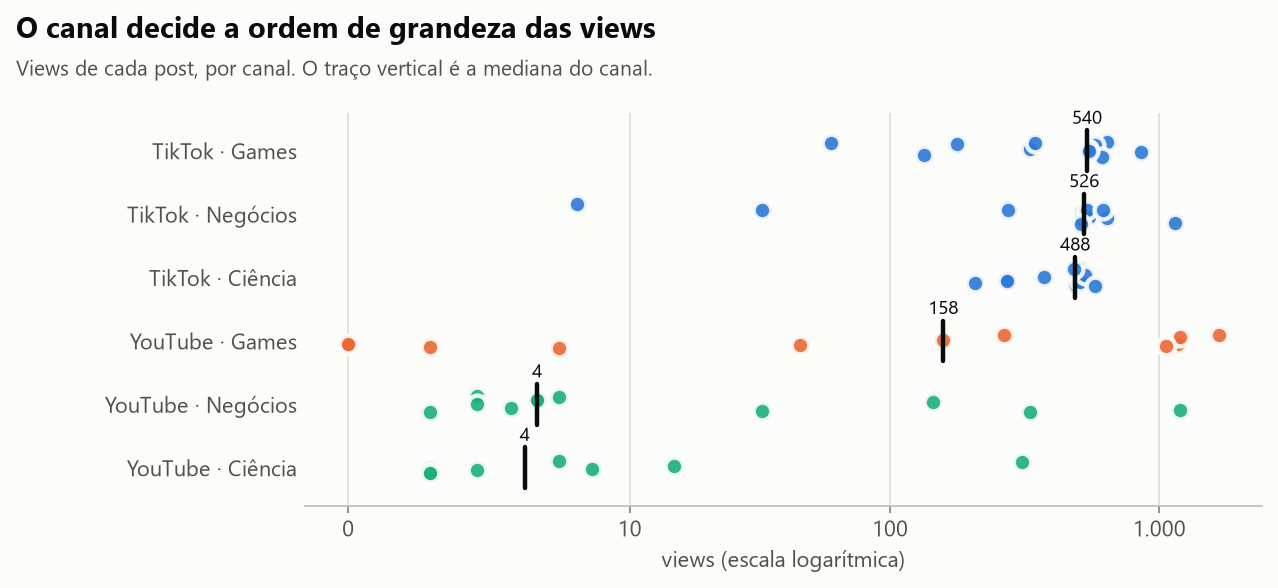

In [3]:
canais = analise.views_por_canal(tabela)
display(canais)
mostrar(graficos.views_por_canal(tabela, canais))

No TikTok, qualquer corte fica perto de 500 views. No YouTube, os canais de ciência e negócios têm mediana de 4
views, e só o de games tem audiência. E há uma coincidência perigosa: **o nicho de games também recebe as notas
mais altas**.

In [4]:
analise.nota_por_nicho(cortes)

,cortes,mediana,p25,p75
nicho,,,,
Ciência,197,0.521,0.438,0.600
Games,190,0.560,0.488,0.641
Negócios,233,0.509,0.413,0.602


Se o canal com mais audiência é também o que recebe nota maior, a correlação sobe mesmo que a nota não distinga
nada dentro do canal. A comparação justa é **dentro de cada canal**: o posto de cada corte é calculado só entre os
posts do mesmo canal, e a correlação usa esses postos. O intervalo vem de um bootstrap que reamostra cortes
inteiros, porque o mesmo corte aparece nas duas plataformas e as linhas não são independentes.

Dentro do canal: 0.34  IC 95% [0.03 ; 0.58]  p (permutação) = 0.008


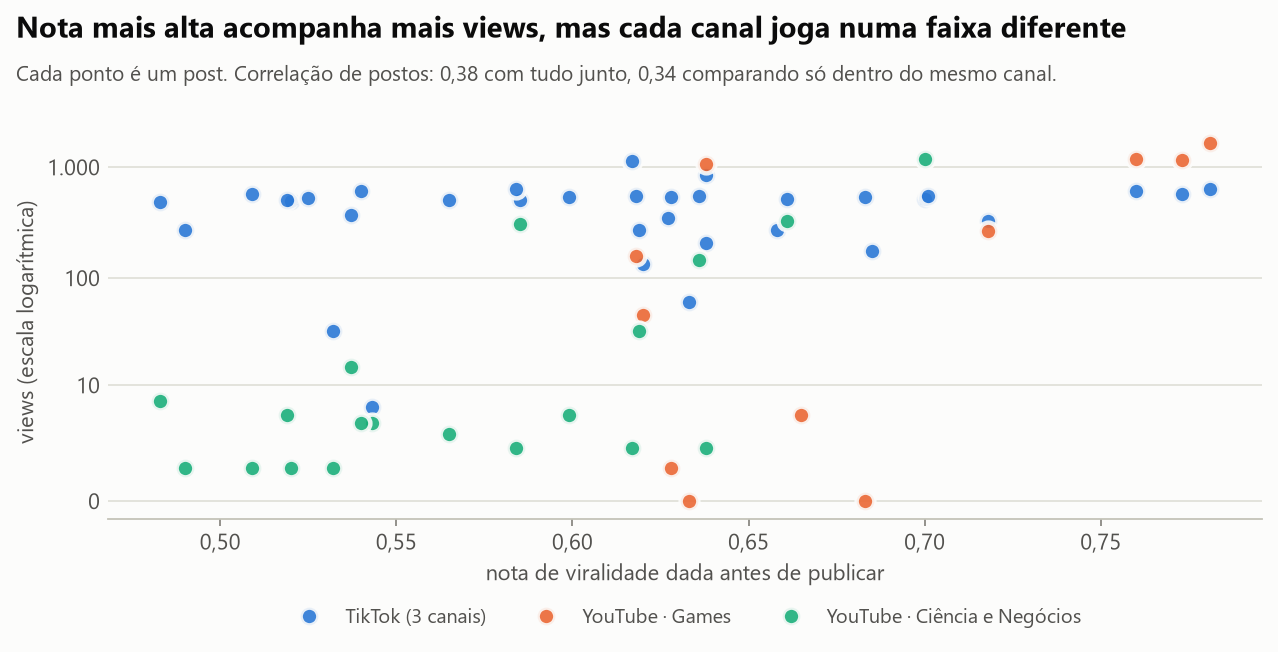

In [5]:
dentro = correlacoes.loc["Dentro de cada canal"]
print(f"Dentro do canal: {dentro['correlação']:.2f}  IC 95% [{dentro['IC 95% inferior']:.2f} ; {dentro['IC 95% superior']:.2f}]  p (permutação) = {dentro['p']:.3f}")
mostrar(graficos.nota_x_views(tabela, ingenua["correlação"], dentro["correlação"]))

A correlação cai pouco, de 0,38 para 0,34, e continua distinta de zero. Parece uma boa notícia: o canal não
explicava tudo. Mas o intervalo vai de 0,03 a 0,58, ou seja, de "quase nada" a "forte".

## 3. Segunda correção: os posts não têm a mesma idade

Há duas coletas de métricas. Comparando as views do mesmo post nas duas:

In [6]:
crescimento = analise.crescimento_entre_coletas(posts)
display(crescimento)
display(analise.views_por_idade(tabela))

posts  ganho_mediano  ganho_relativo_mediano
plataforma mais_de_um_dia                                              
tiktok     False              11        138.000                   0.931
           True               20          1.000                   0.003
youtube    False               9          1.000                   0.239
           True               18          0.000                   0.000

posts  views_mediana  nota_mediana
plataforma horas_no_ar                                      
tiktok     menos de 24 h     12        517.000         0.635
           24 a 48 h         14        522.000         0.575
           mais de 48 h       8        498.000         0.629
youtube    menos de 24 h     10         76.000         0.635
           24 a 48 h         11          4.000         0.565
           mais de 48 h       9          5.000         0.638

Duas coisas aparecem:

- **As views chegam no primeiro dia.** Um post do TikTok com mais de 24 horas ganhou, em mediana, 1 view entre uma
  coleta e outra. Quem tem menos de um dia ainda está subindo.
- **O lote mais recente do YouTube é diferente dos anteriores:** mediana de 76 views contra 4 ou 5. Algo mudou de
  um dia para o outro (a fonte dos cortes, o canal, o horário), e isso não tem a ver com a nota.

Então a pergunta precisa de mais um recorte: a correlação se mantém entre os posts com views já estabilizadas?

,posts,correlação,IC 95% inferior,IC 95% superior,p
comparação,,,,,
Tudo junto (ingênua),64,0.385,0.133,0.596,0.002
Dentro de cada canal,64,0.338,0.030,0.577,0.008
"Dentro do canal, posts com mais de 24 h",42,0.078,-0.300,0.442,0.643
"Dentro do canal, posts com menos de 24 h",22,0.703,-0.026,0.932,0.004


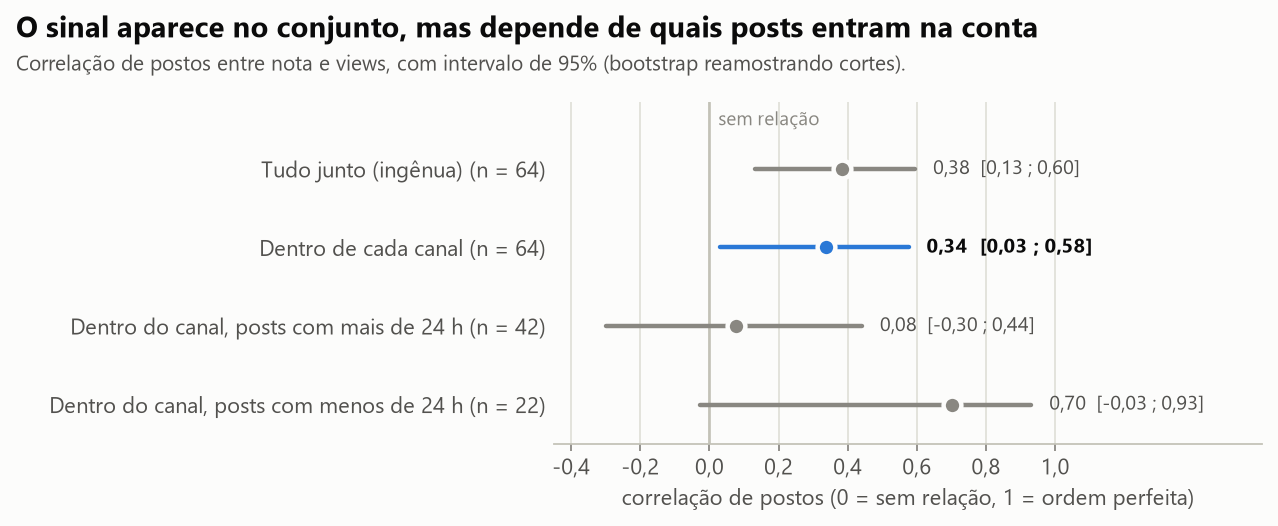

In [7]:
display(correlacoes)
mostrar(graficos.correlacoes(correlacoes))

Não se mantém. **Entre os 42 posts com mais de 24 horas, a correlação dentro do canal é 0,08**, com intervalo de
−0,30 a 0,44. O sinal de 0,34 vinha quase todo dos 22 posts mais novos, onde a correlação é 0,70, com um intervalo
que vai de −0,03 a 0,93.

O que isso quer dizer: com 64 posts publicados em quatro dias, **não dá para separar o efeito da nota do efeito do
lote do dia**. A estimativa muda de 0,08 para 0,70 conforme o recorte, e isso é instabilidade, não descoberta.

Mais duas checagens na mesma direção:

In [8]:
display(analise.checagens(tabela))
ganho = analise.ganho_da_nota_alta(tabela)
print(f"Views dos cortes de nota acima da mediana do canal, em relação aos de nota abaixo: {ganho['razao_de_views']:.2f} vezes  IC 95% [{ganho['ic95_inferior']:.2f} ; {ganho['ic95_superior']:.2f}]")

,posts,correlação dentro do canal,IC 95% inferior,IC 95% superior
checagem,,,,
Todos os posts,64,0.338,0.030,0.577
Sem o post de mais views de cada canal,58,0.306,-0.066,0.577
Dentro do canal e do dia de publicação,64,0.195,-0.209,0.512


Views dos cortes de nota acima da mediana do canal, em relação aos de nota abaixo: 1.06 vezes  IC 95% [0.98 ; 2.78]


Tirando o post de mais views de cada canal, o intervalo passa a incluir o zero. Comparando só posts do mesmo canal
publicados no mesmo dia, a correlação cai para 0,19, também com o zero dentro do intervalo. E em views: os cortes
de nota acima da mediana do canal renderam 1,06 vez as views dos de nota abaixo, com um intervalo de 0,98 a 2,78.

## 4. Alguma parte da nota funciona melhor?

A nota tem duas partes (juiz de IA e métricas do vídeo de origem), e o juiz dá oito notas por critério. São dez
testes na mesma amostra pequena, então os p-valores são ajustados para a taxa de falsas descobertas
(Benjamini-Hochberg):

In [9]:
analise.componentes_da_nota(tabela)

,correlação ingênua,correlação dentro do canal,p,p ajustado
componente,,,,
ensina algo,-0.039,0.271,0.038,0.292
gancho nos 3 primeiros segundos,0.191,0.247,0.058,0.292
humor,0.213,0.214,0.111,0.306
dá vontade de compartilhar,0.090,0.202,0.128,0.306
nota do juiz de IA,0.073,0.183,0.153,0.306
nota das métricas do vídeo de origem,0.292,0.124,0.346,0.576
"começo, meio e fim",-0.084,-0.114,0.405,0.579
energia,0.055,0.069,0.624,0.710
faz sentido sozinho,-0.008,0.064,0.639,0.710


Nenhum componente resiste à correção. "Ensina algo" e "gancho nos 3 primeiros segundos" têm os menores p-valores
brutos (0,04 e 0,06), mas com dez testes isso é o que se espera ver por acaso. Ficam como hipóteses para a próxima
leitura, não como achados.

Um detalhe de leitura: a parte "métricas do vídeo de origem" tem correlação ingênua de 0,29 e cai para 0,12 dentro
do canal. Ela carrega o nicho, então boa parte do que ela "acerta" é adivinhar o canal.

## 5. Duas limitações de desenho que nenhuma amostra maior resolve sozinha

In [10]:
display(pd.Series(analise.restricao_de_faixa(cortes, tabela, dentro["correlação"]), name="valor").to_frame())
display(pd.Series(analise.limiar_de_aprovacao(cortes), name="valor").to_frame())

,valor
nota_p10_todos,0.336
nota_p90_todos,0.668
nota_p10_publicados,0.519
nota_p90_publicados,0.711
desvio_todos,0.134
desvio_publicados,0.080
correlacao_observada,0.338
correlacao_corrigida,0.517


,valor
limiar,0.800
nota_maxima,0.799
cortes_no_limiar,0.000
cortes_acima_de_0_70,43.000
total,680.000


- **Só os cortes de nota alta vão ao ar.** Os 680 cortes pontuados têm nota entre 0,34 e 0,67 (do 10º ao 90º
  percentil); os publicados, entre 0,52 e 0,71. Medir numa faixa estreita encolhe qualquer correlação, e não há
  como saber quantas views teria um corte de nota 0,30, porque nenhum foi publicado. A correção de Thorndike sugere
  que 0,34 na faixa restrita corresponderia a cerca de 0,52 na faixa inteira, mas ela depende de suposições que
  estes dados não permitem conferir. Vale como ordem de grandeza.
- **O limiar de aprovação nunca é atingido.** O pipeline aprova cortes com nota a partir de 0,80. A maior nota
  entre os 680 é 0,799: **nenhum corte foi aprovado pelo critério escrito**, e o que se publica são os melhores
  disponíveis. O limiar precisa ser recalibrado, ou a nota, reescalada.

## 6. Quanto dado falta

Hoje: 64 posts → menor correlação detectável: 0.34
Contando cortes em vez de posts (35): 0.46


,posts necessários,semana em que a agenda chega lá
correlação a detectar,,
0.500,30,2026-11-02
0.400,47,2026-11-09
0.300,85,2026-11-09
0.200,194,2026-11-23


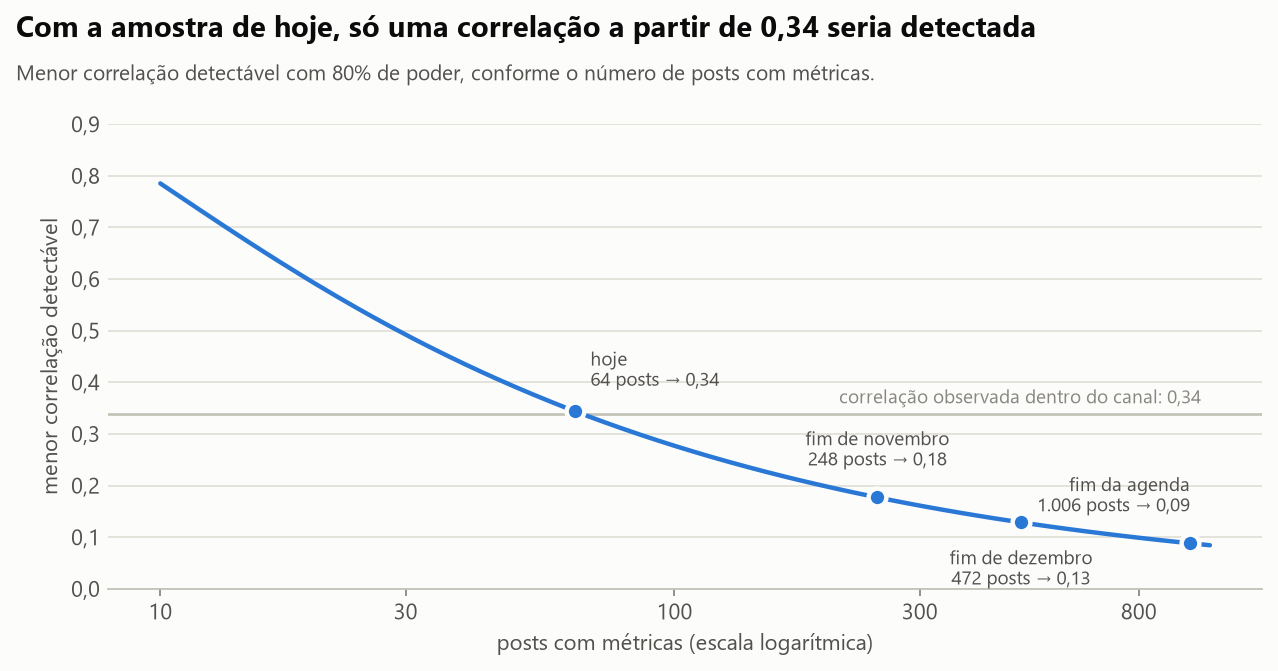

In [11]:
plano = analise.plano_de_amostra(tabela, agenda)
print(f"Hoje: {plano.attrs['posts_hoje']} posts → menor correlação detectável: {plano.attrs['detectavel_hoje']:.2f}")
print(f"Contando cortes em vez de posts ({tabela['corte'].nunique()}): {plano.attrs['detectavel_por_cortes']:.2f}")
display(plano)

marcos = analise.marcos_da_agenda(agenda, len(tabela))
curva = analise.curva_de_poder(1100)
mostrar(graficos.poder(curva, marcos, dentro["correlação"]))

Com 64 posts, o teste só detecta, com 80% de poder, uma correlação de 0,34 ou mais. Uma nota útil mas modesta
(correlação de 0,2) exige 194 posts. A agenda já programada chega a 248 posts no fim de novembro e a 472 no fim de
dezembro, e a coleta de métricas roda todo dia. **A partir do fim de novembro esta análise tem amostra para
responder**, e mais dias de publicação para separar o efeito do lote.

## Conclusões

1. **Ainda não dá para dizer que a nota prevê as views.** A correlação ingênua de 0,38 cai para 0,34 dentro do canal
   e para 0,08 entre os posts com views estabilizadas. A estimativa é instável demais para sustentar uma decisão.
2. **Cada correção tirou um fator que não era a nota:** primeiro a audiência do canal, depois a idade do post e o
   lote do dia. Quem para na primeira conta atribui à nota o que é do canal.
3. **O canal explica mais que o corte.** A mediana vai de 4 a 540 views conforme o canal. Para a operação, decidir
   onde publicar pesa mais do que decidir qual corte publicar.
4. **O limiar de aprovação de 0,80 não aprova nada:** 0 de 680 cortes.
5. **O que fazer:** manter a coleta diária; refazer a leitura com 200 posts ou mais; medir as views sempre com 24
   horas ou mais; e publicar de propósito uma amostra sorteada de cortes de nota baixa, que é o único jeito de
   saber o que a nota está descartando.

## Limitações

- **Amostra pequena e concentrada:** 64 posts de 35 cortes, publicados em quatro dias.
- **Uma métrica só:** views. Retenção e tempo assistido existem para o TikTok e ficam para a próxima leitura.
- **Não é experimento.** A ordem de publicação não foi sorteada; a nota pode estar ligada ao dia e ao horário.
- **Seleção:** só há resultado para os cortes que a própria nota escolheu publicar.
- **Views com menos de 24 horas ainda sobem**, e 22 dos 64 posts estão nessa situação.
- **A nota mudou de versão ao longo do tempo** (os pesos são recalibrados); aqui todas as versões estão juntas.